# Experiment 2: Image Compression Using K-Means

**Aim:** Compress an image of size 396 × 396 × 3 by clustering similar RGB pixel colours into K groups.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.cluster import KMeans
from google.colab import files

## 1. Upload an image

In [2]:
uploaded = files.upload()
image_path = next(iter(uploaded))
print('Uploaded file:', image_path)

Saving 5872224.jpg to 5872224.jpg
Uploaded file: 5872224.jpg


## 2. Resize the image to 396 × 396 × 3

Image shape: (396, 396, 3)
Number of pixels: 156816


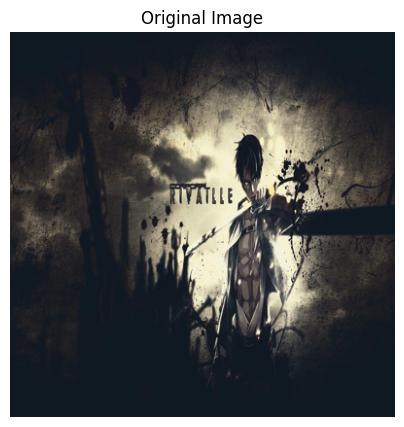

In [3]:
image = Image.open(image_path).convert('RGB').resize((396, 396))
image_array = np.asarray(image)
pixels = image_array.reshape(-1, 3).astype(np.float32)
print('Image shape:', image_array.shape)
print('Number of pixels:', pixels.shape[0])

plt.figure(figsize=(5, 5))
plt.imshow(image_array)
plt.title('Original Image')
plt.axis('off')
plt.show()

## 3. Apply K-Means to cluster pixel colours

In [4]:
# Change K to use a different number of colours.
K = 16
kmeans = KMeans(n_clusters=K, init='k-means++', n_init=3, random_state=42)
labels = kmeans.fit_predict(pixels)
compressed_pixels = kmeans.cluster_centers_[labels].clip(0, 255).astype(np.uint8)
compressed_image = compressed_pixels.reshape(396, 396, 3)
print(f'Image compressed to at most {K} representative colours.')

Image compressed to at most 16 representative colours.


## 4. Compare original and compressed images

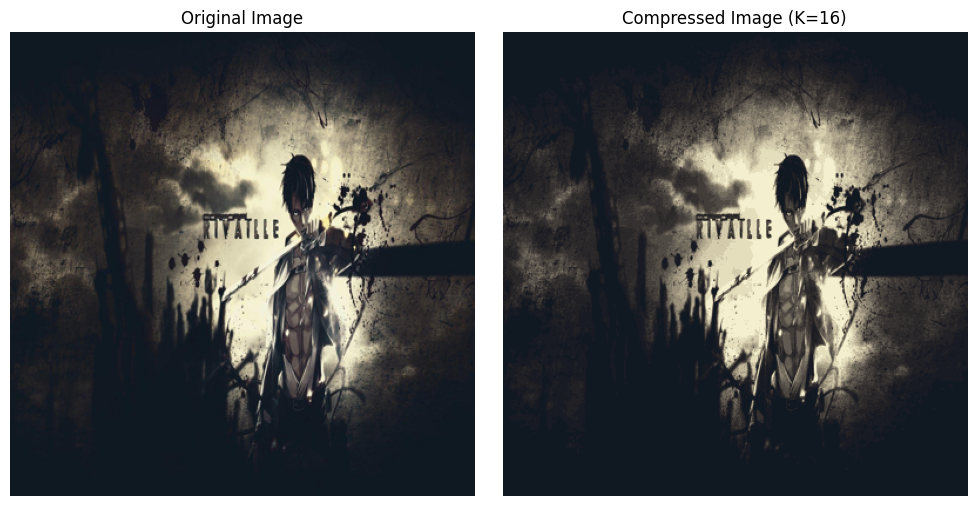

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image_array)
axes[0].set_title('Original Image')
axes[0].axis('off')
axes[1].imshow(compressed_image)
axes[1].set_title(f'Compressed Image (K={K})')
axes[1].axis('off')
plt.tight_layout()
plt.show()

## 5. Save and download the compressed image

In [6]:
output_path = 'compressed_image_kmeans.png'
Image.fromarray(compressed_image).save(output_path)
files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Result
The image was resized to 396 × 396 × 3 and compressed by replacing each pixel with one of K cluster-centroid colours. A smaller K gives stronger compression but may reduce image quality.